In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("SOLAR POWER MONITORING SYSTEM")
print("--------------------------------")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Environment is ready!")

SOLAR POWER MONITORING SYSTEM
--------------------------------
Pandas: 3.1.1
NumPy: 2.5.5
Scikit-learn: 1.9.1
Environment is ready!


# Solar Power Generation Prediction and Performance Deviation Analysis

## 1. Project Overview

This project aims to develop a Machine Learning-based solar power monitoring system that predicts electricity generation using environmental and generation measurements.

The system compares actual power generation with predicted generation to identify unusual performance deviations.

## 2. Project Objectives

1. Analyze solar power generation data.
2. Study the relationship between weather conditions and solar generation.
3. Develop Linear Regression, Random Forest Regression and Support Vector Regression models.
4. Evaluate models using MAE, RMSE and R-squared.
5. Detect unusual performance deviations using residual analysis.
6. Develop a monitoring system for solar power plants.

## 3. Dataset

Source: Kaggle – Solar Power Generation Data

The dataset contains generation measurements and weather sensor measurements from two solar power plants.

## 4. Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

In [3]:
from pathlib import Path

# Find the project directory automatically
current_path = Path.cwd()

PROJECT_ROOT = next(
    (path for path in [current_path, *current_path.parents]
     if (path / "data").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project data folder not found!")

# Dataset directory
DATA_DIR = PROJECT_ROOT / "data"

print("Project Directory:", PROJECT_ROOT)
print("Dataset Directory:", DATA_DIR)

# Find CSV files
csv_files = list(DATA_DIR.glob("*.csv"))

print("\nAvailable CSV Files:")

for file in csv_files:
    print(file.name)

print("\nTotal CSV Files:", len(csv_files)) 

Project Directory: c:\Users\MANUPATI PAVAN\OneDrive\Desktop\Solar_Power_Monitoring_System
Dataset Directory: c:\Users\MANUPATI PAVAN\OneDrive\Desktop\Solar_Power_Monitoring_System\data

Available CSV Files:
Plant_1_Generation_Data.csv
Plant_1_Weather_Sensor_Data.csv
Plant_2_Generation_Data.csv
Plant_2_Weather_Sensor_Data.csv

Total CSV Files: 4


## 5. Dataset Loading

In this section, we load the four CSV datasets obtained from Kaggle.

The datasets contain solar power generation measurements and weather sensor readings from two solar power plants.

We use Pandas to load and manipulate the datasets.

In [4]:
# Import required library
import pandas as pd

# Load Plant 1 datasets
plant1_gen = pd.read_csv(DATA_DIR / "Plant_1_Generation_Data.csv")
plant1_weather = pd.read_csv(DATA_DIR / "Plant_1_Weather_Sensor_Data.csv")

# Load Plant 2 datasets
plant2_gen = pd.read_csv(DATA_DIR / "Plant_2_Generation_Data.csv")
plant2_weather = pd.read_csv(DATA_DIR / "Plant_2_Weather_Sensor_Data.csv")

print("ALL FOUR DATASETS LOADED SUCCESSFULLY!")

ALL FOUR DATASETS LOADED SUCCESSFULLY!


In [5]:
# Display dataset dimensions

print("PLANT 1 GENERATION:", plant1_gen.shape)
print("PLANT 1 WEATHER:", plant1_weather.shape)

print("PLANT 2 GENERATION:", plant2_gen.shape)
print("PLANT 2 WEATHER:", plant2_weather.shape)

PLANT 1 GENERATION: (68778, 7)
PLANT 1 WEATHER: (3182, 6)
PLANT 2 GENERATION: (67698, 7)
PLANT 2 WEATHER: (3259, 6)


In [6]:
print("PLANT 1 GENERATION DATA")
display(plant1_gen.head())

print("PLANT 1 WEATHER DATA")
display(plant1_weather.head())

print("PLANT 2 GENERATION DATA")
display(plant2_gen.head())

print("PLANT 2 WEATHER DATA")
display(plant2_weather.head())

PLANT 1 GENERATION DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 0.00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 0.00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 0.00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 0.00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 0.00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


PLANT 1 WEATHER DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,15-05-2020 0.00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,15-05-2020 0.15,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,15-05-2020 0.30,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,15-05-2020 0.45,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,15-05-2020 1.00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


PLANT 2 GENERATION DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 0.00,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06
1,15-05-2020 0.00,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09
2,15-05-2020 0.00,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09
3,15-05-2020 0.00,4136001,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06
4,15-05-2020 0.00,4136001,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07


PLANT 2 WEATHER DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,15-05-2020 0.00,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
1,15-05-2020 0.15,4136001,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
2,15-05-2020 0.30,4136001,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0
3,15-05-2020 0.45,4136001,iq8k7ZNt4Mwm3w0,26.500589,24.420678,0.0
4,15-05-2020 1.00,4136001,iq8k7ZNt4Mwm3w0,26.596148,25.088210,0.0


In [7]:
print("PLANT 1 GENERATION")
plant1_gen.info()

print("\nPLANT 1 WEATHER")
plant1_weather.info()

print("\nPLANT 2 GENERATION")
plant2_gen.info()

print("\nPLANT 2 WEATHER")
plant2_weather.info()

PLANT 1 GENERATION
<class 'pandas.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  str    
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  str    
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), str(2)
memory usage: 5.7 MB

PLANT 1 WEATHER
<class 'pandas.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            3182 non-null   str    
 1   PLANT_ID             3182 non-null   int64  
 2   SOURCE_KEY           3182 non-null   str    
 3   AMBIENT_TEMPERATURE  3182 non-null   float64
 4   MODULE_TEMPERATURE   3182 non-n

In [8]:
datasets = {
    "Plant 1 Generation": plant1_gen,
    "Plant 1 Weather": plant1_weather,
    "Plant 2 Generation": plant2_gen,
    "Plant 2 Weather": plant2_weather
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Plant 1 Generation: (68778, 7)
Plant 1 Weather: (3182, 6)
Plant 2 Generation: (67698, 7)
Plant 2 Weather: (3259, 6)


In [9]:
for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(df.isnull().sum())


Plant 1 Generation
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 1 Weather
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Plant 2 Generation
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 2 Weather
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64


In [10]:
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate records"
    ) 

Plant 1 Generation: 0 duplicate records
Plant 1 Weather: 0 duplicate records
Plant 2 Generation: 0 duplicate records
Plant 2 Weather: 0 duplicate records


In [11]:
for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    display(df.describe())


Plant 1 Generation


,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,68778.0,68778.000000,68778.000000,68778.000000,6.877800e+04
mean,4135001.0,3147.426211,307.802752,3295.968737,6.978712e+06
std,0.0,4036.457169,394.396439,3145.178309,4.162720e+05
min,4135001.0,0.000000,0.000000,0.000000,6.183645e+06
25%,4135001.0,0.000000,0.000000,0.000000,6.512003e+06
50%,4135001.0,429.000000,41.493750,2658.714286,7.146685e+06
75%,4135001.0,6366.964286,623.618750,6274.000000,7.268706e+06
max,4135001.0,14471.125000,1410.950000,9163.000000,7.846821e+06



Plant 1 Weather


,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3182.0,3182.000000,3182.000000,3182.000000
mean,4135001.0,25.531606,31.091015,0.228313
std,0.0,3.354856,12.261222,0.300836
min,4135001.0,20.398505,18.140415,0.000000
25%,4135001.0,22.705182,21.090553,0.000000
50%,4135001.0,24.613814,24.618060,0.024653
75%,4135001.0,27.920532,41.307840,0.449588
max,4135001.0,35.252486,65.545714,1.221652



Plant 2 Generation


,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,67698.0,67698.000000,67698.000000,67698.000000,6.769800e+04
mean,4136001.0,246.701961,241.277825,3294.890295,6.589448e+08
std,0.0,370.569597,362.112118,2919.448386,7.296678e+08
min,4136001.0,0.000000,0.000000,0.000000,0.000000e+00
25%,4136001.0,0.000000,0.000000,272.750000,1.996494e+07
50%,4136001.0,0.000000,0.000000,2911.000000,2.826276e+08
75%,4136001.0,446.591667,438.215000,5534.000000,1.348495e+09
max,4136001.0,1420.933333,1385.420000,9873.000000,2.247916e+09



Plant 2 Weather


,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3259.0,3259.000000,3259.000000,3259.000000
mean,4136001.0,28.069400,32.772408,0.232737
std,0.0,4.061556,11.344034,0.312693
min,4136001.0,20.942385,20.265123,0.000000
25%,4136001.0,24.602135,23.716881,0.000000
50%,4136001.0,26.981263,27.534606,0.019040
75%,4136001.0,31.056757,40.480653,0.438717
max,4136001.0,39.181638,66.635953,1.098766


In [12]:
# Dataset quality analysis

for name, df in datasets.items():

    print("\n" + "=" * 55)
    print("DATASET:", name)
    print("=" * 55)

    print("Total Rows:", df.shape[0])
    print("Total Columns:", df.shape[1])

    print("\nMissing Values:")
    print(df.isnull().sum().to_string())

    print("\nTotal Missing Values:", df.isnull().sum().sum())

    print("\nDuplicate Records:", df.duplicated().sum())


DATASET: Plant 1 Generation
Total Rows: 68778
Total Columns: 7

Missing Values:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0

Total Missing Values: 0

Duplicate Records: 0

DATASET: Plant 1 Weather
Total Rows: 3182
Total Columns: 6

Missing Values:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0

Total Missing Values: 0

Duplicate Records: 0

DATASET: Plant 2 Generation
Total Rows: 67698
Total Columns: 7

Missing Values:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0

Total Missing Values: 0

Duplicate Records: 0

DATASET: Plant 2 Weather
Total Rows: 3259
Total Columns: 6

Missing Values:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0

Tota

In [13]:
print("PLANT 1 GENERATION")
display(plant1_gen["DATE_TIME"].head())

print("PLANT 1 WEATHER")
display(plant1_weather["DATE_TIME"].head())

print("PLANT 2 GENERATION")
display(plant2_gen["DATE_TIME"].head())

print("PLANT 2 WEATHER")
display(plant2_weather["DATE_TIME"].head())

PLANT 1 GENERATION


0    15-05-2020 0.00
1    15-05-2020 0.00
2    15-05-2020 0.00
3    15-05-2020 0.00
4    15-05-2020 0.00
Name: DATE_TIME, dtype: str

PLANT 1 WEATHER


0    15-05-2020 0.00
1    15-05-2020 0.15
2    15-05-2020 0.30
3    15-05-2020 0.45
4    15-05-2020 1.00
Name: DATE_TIME, dtype: str

PLANT 2 GENERATION


0    15-05-2020 0.00
1    15-05-2020 0.00
2    15-05-2020 0.00
3    15-05-2020 0.00
4    15-05-2020 0.00
Name: DATE_TIME, dtype: str

PLANT 2 WEATHER


0    15-05-2020 0.00
1    15-05-2020 0.15
2    15-05-2020 0.30
3    15-05-2020 0.45
4    15-05-2020 1.00
Name: DATE_TIME, dtype: str

In [14]:
# Create copies to preserve original datasets

plant1_gen_clean = plant1_gen.copy()
plant1_weather_clean = plant1_weather.copy()

plant2_gen_clean = plant2_gen.copy()
plant2_weather_clean = plant2_weather.copy()


# Function to convert timestamp format

def convert_datetime(df):
    
    df["DATE_TIME"] = (
        df["DATE_TIME"]
        .astype(str)
        .str.replace(r"(\d{1,2})\.(\d{2})$", r"\1:\2", regex=True)
    )
    
    df["DATE_TIME"] = pd.to_datetime(
        df["DATE_TIME"],
        format="%d-%m-%Y %H:%M",
        errors="coerce"
    )
    
    return df


# Convert timestamps in all four datasets

plant1_gen_clean = convert_datetime(plant1_gen_clean)
plant1_weather_clean = convert_datetime(plant1_weather_clean)

plant2_gen_clean = convert_datetime(plant2_gen_clean)
plant2_weather_clean = convert_datetime(plant2_weather_clean)


print("DATE AND TIME CONVERSION COMPLETED!")

DATE AND TIME CONVERSION COMPLETED!


In [15]:
for name, df in {
    "Plant 1 Generation": plant1_gen_clean,
    "Plant 1 Weather": plant1_weather_clean,
    "Plant 2 Generation": plant2_gen_clean,
    "Plant 2 Weather": plant2_weather_clean
}.items():

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print("Missing values:", df.isnull().sum().sum())

    print("Duplicate rows:", df.duplicated().sum())


Plant 1 Generation
Missing values: 0
Duplicate rows: 0

Plant 1 Weather
Missing values: 0
Duplicate rows: 0

Plant 2 Generation
Missing values: 0
Duplicate rows: 0

Plant 2 Weather
Missing values: 0
Duplicate rows: 0


In [16]:
# Complete data quality report

quality_report = []

for name, df in {
    "Plant 1 Generation": plant1_gen_clean,
    "Plant 1 Weather": plant1_weather_clean,
    "Plant 2 Generation": plant2_gen_clean,
    "Plant 2 Weather": plant2_weather_clean
}.items():

    quality_report.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Invalid Timestamps": df["DATE_TIME"].isna().sum()
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Invalid Timestamps
0,Plant 1 Generation,68778,7,0,0,0
1,Plant 1 Weather,3182,6,0,0,0
2,Plant 2 Generation,67698,7,0,0,0
3,Plant 2 Weather,3259,6,0,0,0


In [17]:
for name, df in {
    "Plant 1 Generation": plant1_gen_clean,
    "Plant 1 Weather": plant1_weather_clean,
    "Plant 2 Generation": plant2_gen_clean,
    "Plant 2 Weather": plant2_weather_clean
}.items():

    print(name)
    print("Data type:", df["DATE_TIME"].dtype)
    print("Invalid timestamps:", df["DATE_TIME"].isna().sum())
    print("Date range:", df["DATE_TIME"].min(), "to", df["DATE_TIME"].max())
    print("-" * 60)

Plant 1 Generation
Data type: datetime64[us]
Invalid timestamps: 0
Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
------------------------------------------------------------
Plant 1 Weather
Data type: datetime64[us]
Invalid timestamps: 0
Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
------------------------------------------------------------
Plant 2 Generation
Data type: datetime64[us]
Invalid timestamps: 0
Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
------------------------------------------------------------
Plant 2 Weather
Data type: datetime64[us]
Invalid timestamps: 0
Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
------------------------------------------------------------


## 6. Data Integration

In this section, generation measurements and weather sensor measurements are combined using their timestamps.

The generation dataset contains multiple inverter readings for each timestamp. Therefore, we aggregate DC_POWER and AC_POWER to calculate total plant-level generation.

Weather measurements are grouped by timestamp, and the average environmental readings are calculated.

Finally, both datasets are merged to create a unified dataset for each solar power plant.

In [18]:
def integrate_plant_data(generation_df, weather_df, plant_number):

    # Aggregate inverter-level generation readings
    generation = (
        generation_df
        .groupby(["DATE_TIME", "PLANT_ID"], as_index=False)
        .agg({
            "DC_POWER": "sum",
            "AC_POWER": "sum",
            "DAILY_YIELD": "sum",
            "TOTAL_YIELD": "sum"
        })
    )

    # Aggregate weather readings
    weather = (
        weather_df
        .groupby(["DATE_TIME", "PLANT_ID"], as_index=False)
        .agg({
            "AMBIENT_TEMPERATURE": "mean",
            "MODULE_TEMPERATURE": "mean",
            "IRRADIATION": "mean"
        })
    )

    # Merge using timestamp and plant ID
    merged = pd.merge(
        generation,
        weather,
        on=["DATE_TIME", "PLANT_ID"],
        how="inner"
    )

    # Add plant identifier
    merged["plant_id"] = plant_number

    return merged.sort_values("DATE_TIME").reset_index(drop=True)

In [19]:
# Integrate Plant 1
plant1_master = integrate_plant_data(
    plant1_gen_clean,
    plant1_weather_clean,
    1
)

# Integrate Plant 2
plant2_master = integrate_plant_data(
    plant2_gen_clean,
    plant2_weather_clean,
    2
)

print("DATA INTEGRATION COMPLETED!")

DATA INTEGRATION COMPLETED!


In [20]:
print("PLANT 1 MASTER DATASET")
print("Shape:", plant1_master.shape)
display(plant1_master.head())

print("\nPLANT 2 MASTER DATASET")
print("Shape:", plant2_master.shape)
display(plant2_master.head())

PLANT 1 MASTER DATASET
Shape: (3157, 10)


,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,plant_id
0,2020-05-15 00:00:00,4135001,0.0,0.0,0.0,143581676.0,25.184316,22.857507,0.0,1
1,2020-05-15 00:15:00,4135001,0.0,0.0,0.0,143581676.0,25.084589,22.761668,0.0,1
2,2020-05-15 00:30:00,4135001,0.0,0.0,0.0,143581676.0,24.935753,22.592306,0.0,1
3,2020-05-15 00:45:00,4135001,0.0,0.0,0.0,143581676.0,24.846130,22.360852,0.0,1
4,2020-05-15 01:00:00,4135001,0.0,0.0,0.0,150761642.0,24.621525,22.165423,0.0,1



PLANT 2 MASTER DATASET
Shape: (3259, 10)


,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,plant_id
0,2020-05-15 00:00:00,4136001,0.0,0.0,48899.938095,1.418960e+10,27.004764,25.060789,0.0,2
1,2020-05-15 00:15:00,4136001,0.0,0.0,28401.000000,1.418960e+10,26.880811,24.421869,0.0,2
2,2020-05-15 00:30:00,4136001,0.0,0.0,28401.000000,1.418960e+10,26.682055,24.427290,0.0,2
3,2020-05-15 00:45:00,4136001,0.0,0.0,28401.000000,1.418960e+10,26.500589,24.420678,0.0,2
4,2020-05-15 01:00:00,4136001,0.0,0.0,26516.000000,1.418960e+10,26.596148,25.088210,0.0,2


In [21]:
print("PLANT 1")
print("Duplicate timestamps:", plant1_master["DATE_TIME"].duplicated().sum())
print("Missing values:", plant1_master.isnull().sum().sum())

print("\nPLANT 2")
print("Duplicate timestamps:", plant2_master["DATE_TIME"].duplicated().sum())
print("Missing values:", plant2_master.isnull().sum().sum())

PLANT 1
Duplicate timestamps: 0
Missing values: 0

PLANT 2
Duplicate timestamps: 0
Missing values: 0


In [22]:
# Combine Plant 1 and Plant 2

solar_data = pd.concat(
    [plant1_master, plant2_master],
    ignore_index=True
)

solar_data = solar_data.sort_values(
    ["DATE_TIME", "plant_id"]
).reset_index(drop=True)

print("FINAL SOLAR DATASET")
print("Total Records:", len(solar_data))
print("Total Columns:", len(solar_data.columns))

display(solar_data.head(10))

FINAL SOLAR DATASET
Total Records: 6416
Total Columns: 10


,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,plant_id
0,2020-05-15 00:00:00,4135001,0.0,0.0,0.000000,1.435817e+08,25.184316,22.857507,0.0,1
1,2020-05-15 00:00:00,4136001,0.0,0.0,48899.938095,1.418960e+10,27.004764,25.060789,0.0,2
2,2020-05-15 00:15:00,4135001,0.0,0.0,0.000000,1.435817e+08,25.084589,22.761668,0.0,1
3,2020-05-15 00:15:00,4136001,0.0,0.0,28401.000000,1.418960e+10,26.880811,24.421869,0.0,2
4,2020-05-15 00:30:00,4135001,0.0,0.0,0.000000,1.435817e+08,24.935753,22.592306,0.0,1
5,2020-05-15 00:30:00,4136001,0.0,0.0,28401.000000,1.418960e+10,26.682055,24.427290,0.0,2
6,2020-05-15 00:45:00,4135001,0.0,0.0,0.000000,1.435817e+08,24.846130,22.360852,0.0,1
7,2020-05-15 00:45:00,4136001,0.0,0.0,28401.000000,1.418960e+10,26.500589,24.420678,0.0,2
8,2020-05-15 01:00:00,4135001,0.0,0.0,0.000000,1.507616e+08,24.621525,22.165423,0.0,1
9,2020-05-15 01:00:00,4136001,0.0,0.0,26516.000000,1.418960e+10,26.596148,25.088210,0.0,2


In [23]:
# Check final dataset

print("SOLAR POWER MASTER DATASET")
print("-" * 50)

print("Total Records:", solar_data.shape[0])
print("Total Columns:", solar_data.shape[1])

print("\nPlant-wise Record Count:")
print(solar_data["plant_id"].value_counts())

print("\nMissing Values:")
print(solar_data.isnull().sum())

print("\nDuplicate Records:", solar_data.duplicated().sum())

print("\nDuplicate Plant-Timestamp Combinations:",
      solar_data.duplicated(["plant_id", "DATE_TIME"]).sum())

print("\nColumn Names:")
print(solar_data.columns.tolist())

SOLAR POWER MASTER DATASET
--------------------------------------------------
Total Records: 6416
Total Columns: 10

Plant-wise Record Count:
plant_id
2    3259
1    3157
Name: count, dtype: int64

Missing Values:
DATE_TIME              0
PLANT_ID               0
DC_POWER               0
AC_POWER               0
DAILY_YIELD            0
TOTAL_YIELD            0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
plant_id               0
dtype: int64

Duplicate Records: 0

Duplicate Plant-Timestamp Combinations: 0

Column Names:
['DATE_TIME', 'PLANT_ID', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'plant_id']


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Visualization libraries ready!")

Visualization libraries ready!


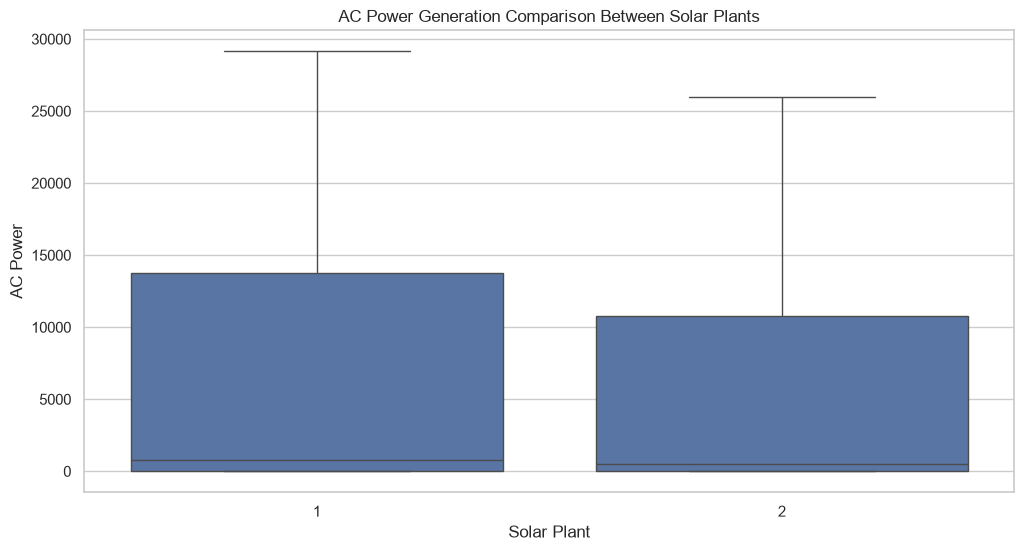

In [25]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=solar_data,
    x="plant_id",
    y="AC_POWER"
)

plt.title("AC Power Generation Comparison Between Solar Plants")
plt.xlabel("Solar Plant")
plt.ylabel("AC Power")
plt.show()

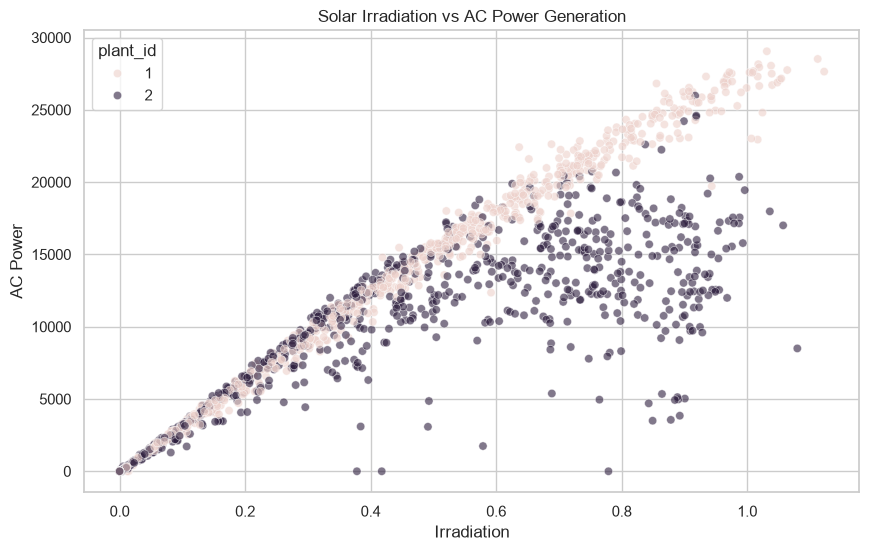

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=solar_data.sample(
        min(3000, len(solar_data)),
        random_state=42
    ),
    x="IRRADIATION",
    y="AC_POWER",
    hue="plant_id",
    alpha=0.6
)

plt.title("Solar Irradiation vs AC Power Generation")
plt.xlabel("Irradiation")
plt.ylabel("AC Power")
plt.show()

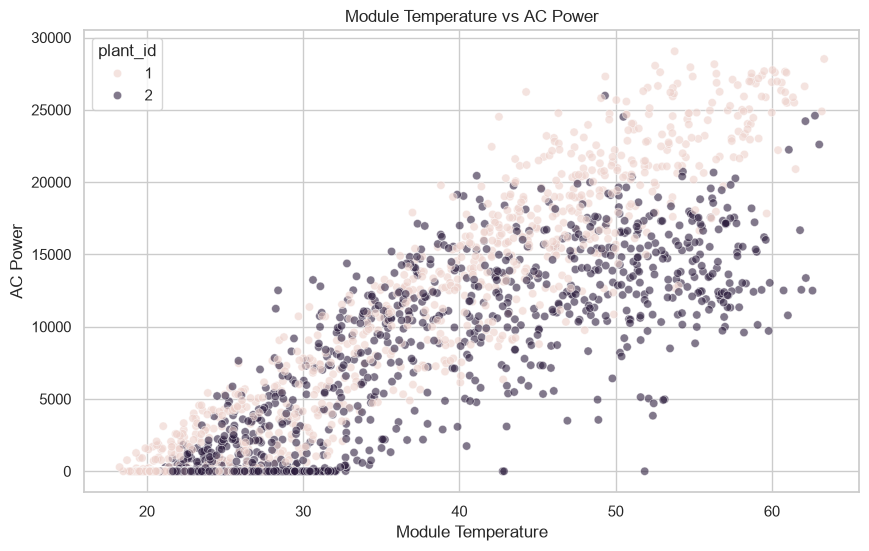

In [27]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=solar_data.sample(
        min(3000, len(solar_data)),
        random_state=42
    ),
    x="MODULE_TEMPERATURE",
    y="AC_POWER",
    hue="plant_id",
    alpha=0.6
)

plt.title("Module Temperature vs AC Power")
plt.xlabel("Module Temperature")
plt.ylabel("AC Power")
plt.show()

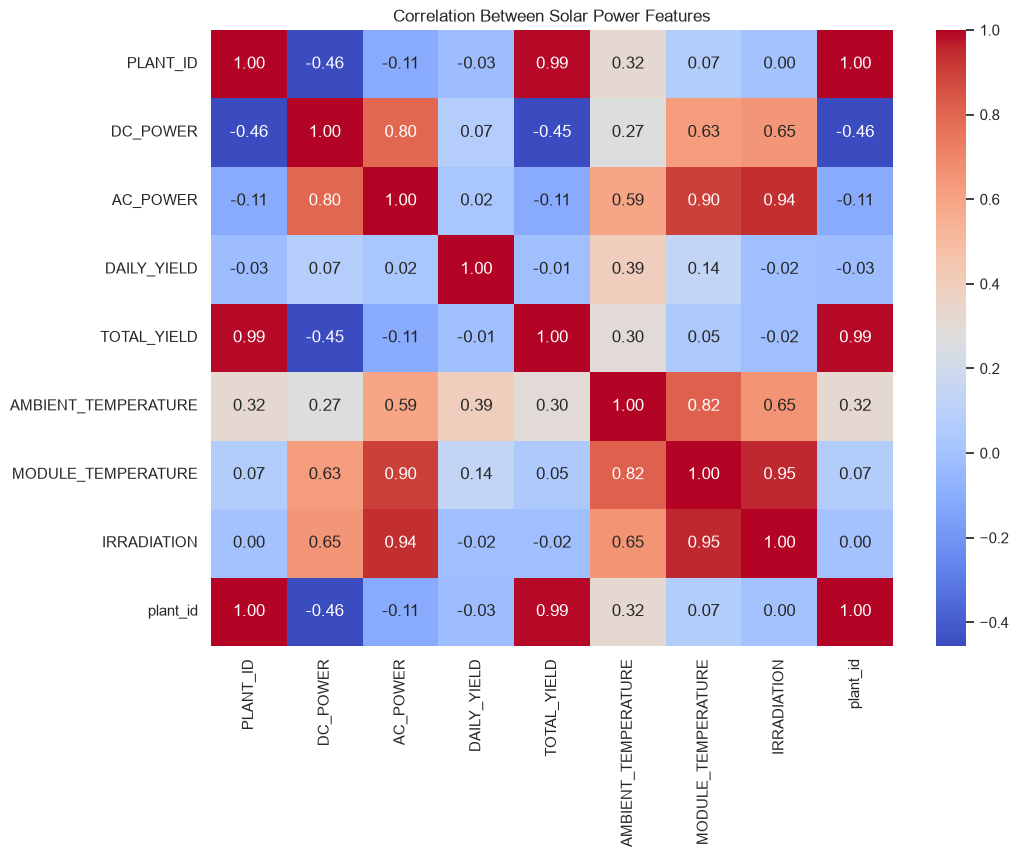

In [28]:
numeric_data = solar_data.select_dtypes(
    include="number"
)

correlation = numeric_data.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Solar Power Features")
plt.show()

## 7. Exploratory Data Analysis – Findings

The exploratory data analysis was performed to understand the relationships between solar power generation and environmental conditions.

### Key Findings

1. Solar irradiation has a strong positive relationship with AC power generation.
2. Module temperature shows a strong positive correlation with AC power in the observed dataset.
3. DC power is strongly associated with AC power generation.
4. Ambient temperature has a moderate positive relationship with AC power.
5. Generation patterns vary between the two solar plants.

### Conclusion

Solar irradiation, DC power, module temperature and ambient temperature are useful candidate features for developing the solar power regression model.

These observations will guide feature selection and model development.

In [29]:
# Create a copy of the master dataset

model_data = solar_data.copy()

# Extract time-related features

model_data["hour"] = model_data["DATE_TIME"].dt.hour

model_data["minute"] = model_data["DATE_TIME"].dt.minute

model_data["day_of_year"] = model_data["DATE_TIME"].dt.dayofyear

model_data["month"] = model_data["DATE_TIME"].dt.month

# Create cyclical time features

import numpy as np

model_data["hour_sin"] = np.sin(
    2 * np.pi * model_data["hour"] / 24
)

model_data["hour_cos"] = np.cos(
    2 * np.pi * model_data["hour"] / 24
)

print("FEATURE ENGINEERING COMPLETED!")

display(model_data.head())

FEATURE ENGINEERING COMPLETED!


C:\Users\MANUPATI PAVAN\AppData\Local\Temp\ipykernel_21480\2048145394.py:11: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  model_data["day_of_year"] = model_data["DATE_TIME"].dt.dayofyear


,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,plant_id,hour,minute,day_of_year,month,hour_sin,hour_cos
0,2020-05-15 00:00:00,4135001,0.0,0.0,0.000000,1.435817e+08,25.184316,22.857507,0.0,1,0,0,136,5,0.0,1.0
1,2020-05-15 00:00:00,4136001,0.0,0.0,48899.938095,1.418960e+10,27.004764,25.060789,0.0,2,0,0,136,5,0.0,1.0
2,2020-05-15 00:15:00,4135001,0.0,0.0,0.000000,1.435817e+08,25.084589,22.761668,0.0,1,0,15,136,5,0.0,1.0
3,2020-05-15 00:15:00,4136001,0.0,0.0,28401.000000,1.418960e+10,26.880811,24.421869,0.0,2,0,15,136,5,0.0,1.0
4,2020-05-15 00:30:00,4135001,0.0,0.0,0.000000,1.435817e+08,24.935753,22.592306,0.0,1,0,30,136,5,0.0,1.0


In [31]:
features = [
    "DC_POWER",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION",
    "hour",
    "minute",
    "day_of_year",
    "hour_sin",
    "hour_cos",
    "plant_id"
]

target = "AC_POWER"

In [32]:
X = model_data[features].copy()

y = model_data[target].copy()

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features Shape: (6416, 10)
Target Shape: (6416,)

Input Features:
   DC_POWER  AMBIENT_TEMPERATURE  MODULE_TEMPERATURE  IRRADIATION  hour  \
0       0.0            25.184316           22.857507          0.0     0   
1       0.0            27.004764           25.060789          0.0     0   
2       0.0            25.084589           22.761668          0.0     0   
3       0.0            26.880811           24.421869          0.0     0   
4       0.0            24.935753           22.592306          0.0     0   

   minute  day_of_year  hour_sin  hour_cos  plant_id  
0       0          136       0.0       1.0         1  
1       0          136       0.0       1.0         2  
2      15          136       0.0       1.0         1  
3      15          136       0.0       1.0         2  
4      30          136       0.0       1.0         1  

Target Values:
0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: AC_POWER, dtype: float64


In [33]:
# Sort data chronologically

model_data = model_data.sort_values(
    "DATE_TIME"
).reset_index(drop=True)

# Identify unique timestamps

unique_dates = np.sort(
    model_data["DATE_TIME"].unique()
)

# Find chronological 80% cutoff

split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

# Split into training and testing

train_data = model_data[
    model_data["DATE_TIME"] < split_date
].copy()

test_data = model_data[
    model_data["DATE_TIME"] >= split_date
].copy()

# Create X and y

X_train = train_data[features]
X_test = test_data[features]

y_train = train_data[target]
y_test = test_data[target]

print("TRAINING DATA:", X_train.shape)
print("TESTING DATA:", X_test.shape)

print("\nTraining period:")
print(train_data["DATE_TIME"].min(), "to",
      train_data["DATE_TIME"].max())

print("\nTesting period:")
print(test_data["DATE_TIME"].min(), "to",
      test_data["DATE_TIME"].max())

TRAINING DATA: (5112, 10)
TESTING DATA: (1304, 10)

Training period:
2020-05-15 00:00:00 to 2020-06-11 04:30:00

Testing period:
2020-06-11 04:45:00 to 2020-06-17 23:45:00


## 8. Machine Learning Model Development

In this section, three regression algorithms are implemented to predict solar power generation.

The algorithms selected are:

1. Linear Regression
2. Random Forest Regression
3. Support Vector Regression (SVR)

The models are trained using 80% of the chronological dataset and evaluated using the remaining 20%.

The performance metrics used are Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [35]:
# Initialize Linear Regression

lr_model = LinearRegression()

# Train model

lr_model.fit(X_train, y_train)

# Generate predictions

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Training Completed!")

Linear Regression Training Completed!


In [36]:
# Initialize Random Forest

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

# Train model

rf_model.fit(X_train, y_train)

# Generate predictions

rf_predictions = rf_model.predict(X_test)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [37]:
# Create SVR pipeline

svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        C=100,
        epsilon=0.1,
        gamma="scale"
    ))
])

# Train model

svr_model.fit(X_train, y_train)

# Generate predictions

svr_predictions = svr_model.predict(X_test)

print("Support Vector Regression Training Completed!")

Support Vector Regression Training Completed!


In [38]:
# Store model predictions

predictions = {
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "SVR": svr_predictions
}

# Calculate evaluation metrics

results = []

for name, prediction in predictions.items():

    mae = mean_absolute_error(y_test, prediction)

    rmse = np.sqrt(
        mean_squared_error(y_test, prediction)
    )

    r2 = r2_score(y_test, prediction)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(results_df)

,Model,MAE,RMSE,R2 Score
0,Random Forest,54.916145,141.006596,0.999577
1,Linear Regression,1350.153877,2049.987445,0.910604
2,SVR,1413.345461,2198.907713,0.897143


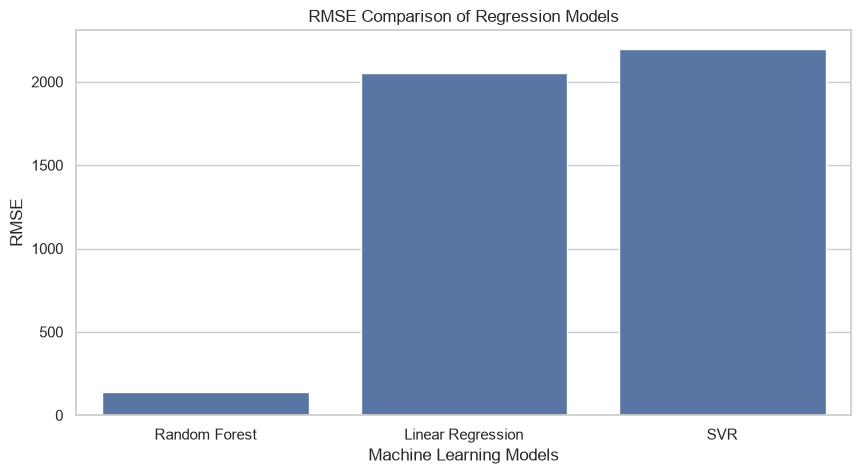

In [39]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Regression Models")
plt.ylabel("RMSE")
plt.xlabel("Machine Learning Models")

plt.show()

In [ ]:
## 9. Model Evaluation and Comparison

Three regression algorithms were trained and evaluated using chronological training and testing datasets.

The Random Forest Regression model achieved the best performance among the three algorithms.

It achieved an MAE of approximately 54.92, RMSE of 141.01 and R-squared of 0.999577.

Therefore, Random Forest Regression was selected as the best-performing model for further performance analysis.

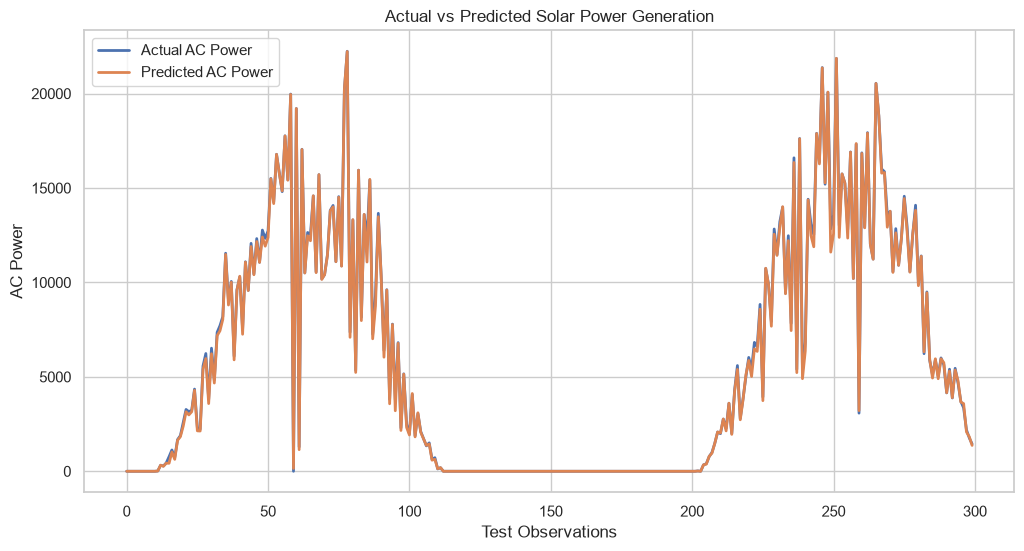

In [40]:
# Actual vs Predicted AC Power

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values[:300],
    label="Actual AC Power",
    linewidth=2
)

plt.plot(
    rf_predictions[:300],
    label="Predicted AC Power",
    linewidth=2
)

plt.title("Actual vs Predicted Solar Power Generation")
plt.xlabel("Test Observations")
plt.ylabel("AC Power")
plt.legend()
plt.grid(True)

plt.show()

In [41]:
# Create residual analysis dataset

residual_data = test_data[
    ["DATE_TIME", "plant_id"]
].copy()

residual_data["Actual_AC_POWER"] = y_test.values

residual_data["Predicted_AC_POWER"] = rf_predictions

# Calculate residual

residual_data["Residual"] = (
    residual_data["Actual_AC_POWER"] -
    residual_data["Predicted_AC_POWER"]
)

# Absolute residual

residual_data["Absolute_Residual"] = (
    residual_data["Residual"].abs()
)

display(residual_data.head(10))

,DATE_TIME,plant_id,Actual_AC_POWER,Predicted_AC_POWER,Residual,Absolute_Residual
5112,2020-06-11 04:45:00,1,0.0,0.0,0.0,0.0
5113,2020-06-11 04:45:00,2,0.0,0.0,0.0,0.0
5114,2020-06-11 05:00:00,2,0.0,0.0,0.0,0.0
5115,2020-06-11 05:00:00,1,0.0,0.0,0.0,0.0
5116,2020-06-11 05:15:00,1,0.0,0.0,0.0,0.0
5117,2020-06-11 05:15:00,2,0.0,0.0,0.0,0.0
5118,2020-06-11 05:30:00,1,0.0,0.0,0.0,0.0
5119,2020-06-11 05:30:00,2,0.0,0.0,0.0,0.0
5120,2020-06-11 05:45:00,1,0.0,0.0,0.0,0.0
5121,2020-06-11 05:45:00,2,0.0,0.0,0.0,0.0


In [42]:
# Use the final 20% of training timestamps for calibration

train_timestamps = np.sort(
    train_data["DATE_TIME"].unique()
)

calibration_index = int(len(train_timestamps) * 0.80)

fit_timestamps = train_timestamps[:calibration_index]

calibration_timestamps = train_timestamps[calibration_index:]

fit_data = train_data[
    train_data["DATE_TIME"].isin(fit_timestamps)
]

calibration_data = train_data[
    train_data["DATE_TIME"].isin(calibration_timestamps)
]

# Train a calibration model on earlier training observations

calibration_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

calibration_model.fit(
    fit_data[features],
    fit_data[target]
)

# Predict on later calibration observations

calibration_predictions = calibration_model.predict(
    calibration_data[features]
)

# Calculate calibration residuals

calibration_residuals = (
    calibration_data[target].values -
    calibration_predictions
)

# Set threshold at 99th percentile of absolute residuals

deviation_threshold = np.percentile(
    np.abs(calibration_residuals),
    99
)

print("Deviation Threshold:", deviation_threshold)

Deviation Threshold: 711.8799842520099


In [43]:
# Classify deviations

residual_data["Deviation_Status"] = np.where(
    residual_data["Absolute_Residual"] > deviation_threshold,
    "Investigate",
    "Normal"
)

print("DEVIATION ANALYSIS RESULTS")

print(
    residual_data["Deviation_Status"].value_counts()
)

display(
    residual_data[
        residual_data["Deviation_Status"] == "Investigate"
    ].head(20)
)

DEVIATION ANALYSIS RESULTS
Deviation_Status
Normal         1294
Investigate      10
Name: count, dtype: int64


,DATE_TIME,plant_id,Actual_AC_POWER,Predicted_AC_POWER,Residual,Absolute_Residual,Deviation_Status
5197,2020-06-11 15:15:00,2,12330.726667,11080.314400,1250.412267,1250.412267,Investigate
5361,2020-06-12 11:45:00,2,12837.900476,11605.629008,1232.271468,1232.271468,Investigate
5362,2020-06-12 12:00:00,2,13577.369524,12587.013496,990.356028,990.356028,Investigate
5951,2020-06-15 13:30:00,2,8715.526190,7868.127530,847.398661,847.398661,Investigate
6145,2020-06-16 13:45:00,2,13727.433333,12801.148993,926.284340,926.284340,Investigate
6159,2020-06-16 15:30:00,2,13877.978571,13094.746289,783.232283,783.232283,Investigate
6300,2020-06-17 09:30:00,2,7643.225238,6887.298851,755.926387,755.926387,Investigate
6305,2020-06-17 10:00:00,2,12028.086667,11181.825393,846.261273,846.261273,Investigate
6345,2020-06-17 15:00:00,2,12178.413333,11021.436821,1156.976513,1156.976513,Investigate
6353,2020-06-17 16:00:00,1,6922.503571,6089.661695,832.841877,832.841877,Investigate


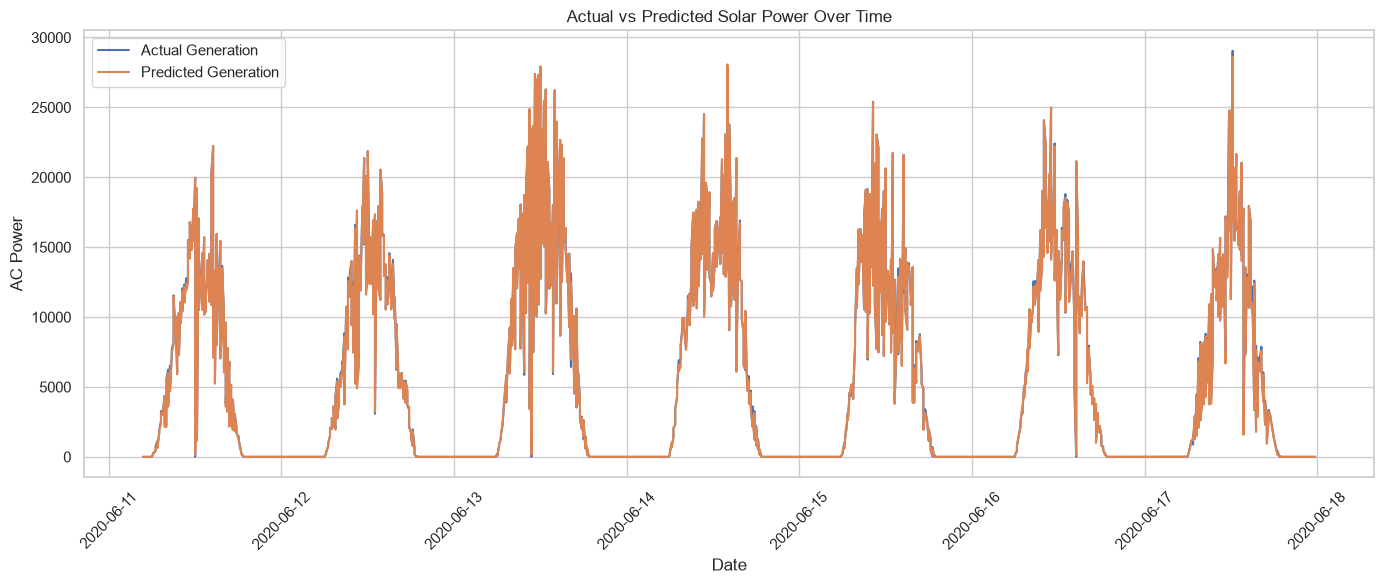

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(
    residual_data["DATE_TIME"],
    residual_data["Actual_AC_POWER"],
    label="Actual Generation"
)

plt.plot(
    residual_data["DATE_TIME"],
    residual_data["Predicted_AC_POWER"],
    label="Predicted Generation"
)

plt.title("Actual vs Predicted Solar Power Over Time")
plt.xlabel("Date")
plt.ylabel("AC Power")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

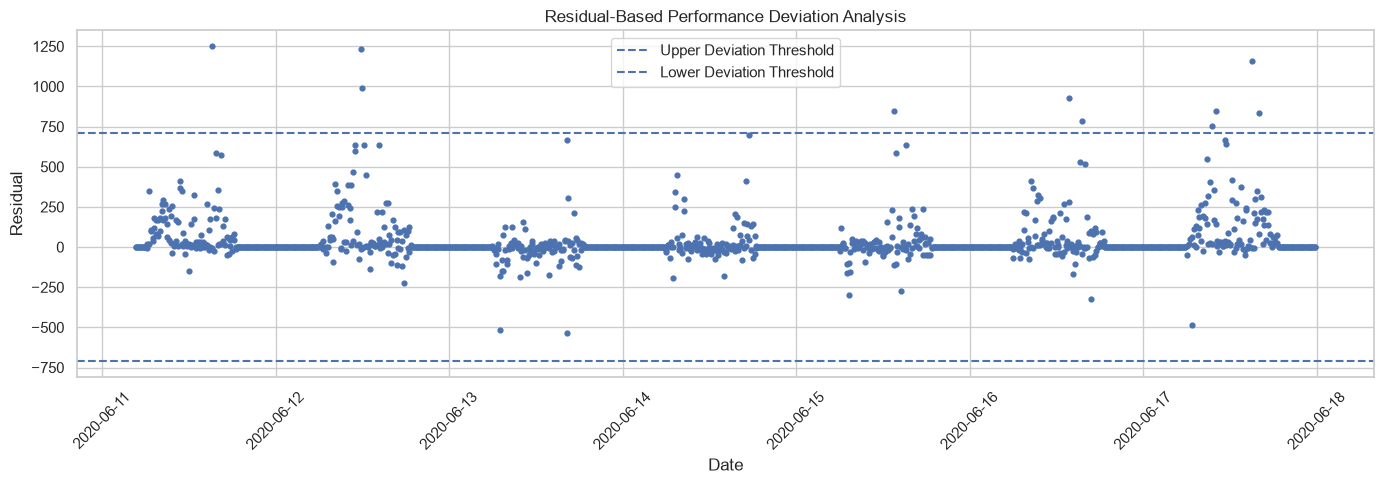

In [45]:
plt.figure(figsize=(14, 5))

plt.scatter(
    residual_data["DATE_TIME"],
    residual_data["Residual"],
    s=12
)

plt.axhline(
    deviation_threshold,
    linestyle="--",
    label="Upper Deviation Threshold"
)

plt.axhline(
    -deviation_threshold,
    linestyle="--",
    label="Lower Deviation Threshold"
)

plt.title("Residual-Based Performance Deviation Analysis")
plt.xlabel("Date")
plt.ylabel("Residual")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [46]:
import joblib
from pathlib import Path

# Create model directory

MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(exist_ok=True)

# Save Random Forest model

model_path = MODEL_DIR / "solar_model.pkl"

joblib.dump(rf_model, model_path)

print("MODEL SAVED SUCCESSFULLY!")
print("Location:", model_path)

MODEL SAVED SUCCESSFULLY!
Location: c:\Users\MANUPATI PAVAN\OneDrive\Desktop\Solar_Power_Monitoring_System\models\solar_model.pkl


In [47]:
model_config = {
    "features": features,
    "target": target,
    "model_name": "Random Forest Regression",
    "deviation_threshold": float(deviation_threshold)
}

joblib.dump(
    model_config,
    MODEL_DIR / "model_config.pkl"
)

print("Model configuration saved!")

Model configuration saved!


In [48]:
import json

# Select a realistic daytime observation from test data

sample = test_data[
    (test_data["IRRADIATION"] > 0.2) &
    (test_data["AC_POWER"] > 100)
].iloc[0]

# Create API testing payload

test_payload = {
    "timestamp": sample["DATE_TIME"].strftime("%Y-%m-%dT%H:%M:%S"),
    "plant_id": int(sample["plant_id"]),
    "dc_power": float(sample["DC_POWER"]),
    "ambient_temperature": float(sample["AMBIENT_TEMPERATURE"]),
    "module_temperature": float(sample["MODULE_TEMPERATURE"]),
    "irradiation": float(sample["IRRADIATION"]),
    "actual_ac_power": float(sample["AC_POWER"])
}

print(json.dumps(test_payload, indent=4))

{
    "timestamp": "2020-06-11T08:45:00",
    "plant_id": 1,
    "dc_power": 74854.57143,
    "ambient_temperature": 24.06972253,
    "module_temperature": 30.36452833,
    "irradiation": 0.219947506,
    "actual_ac_power": 7359.1142858
}
